# PRESELECCIÓN DE VARIABLES

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sql

from sklearn.feature_selection import mutual_info_regression
from sklearn.feature_selection import RFE
from xgboost import XGBRegressor
from sklearn.inspection import permutation_importance

#desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.5f' % x)
np.set_printoptions(suppress=True)

# ── Rutas del proyecto ────────────────────────────────────────────────
# Se resuelven desde la ubicación del notebook, así funcionan
# igual en cualquier máquina
RAIZ = Path.cwd().parent

ORIGINALES   = RAIZ / '02_datos' / '01_Originales'
VALIDACION   = RAIZ / '02_datos' / '02_Validacion'
ENTRENAMIENTO = RAIZ / '02_datos' / '03_Entrenamiento'
CACHES       = RAIZ / '02_datos' / '04_Caches'
MODELOS      = RAIZ / '05_modelos'
RESULTADOS   = RAIZ / '06_resultados'

# ── Variables de entorno ──────────────────────────────────────────────
load_dotenv(RAIZ / '.env')

print('✅ Entorno listo')
print(f'   Raíz del proyecto: {RAIZ}')

✅ Entorno listo
   Raíz del proyecto: c:\Users\Admin\Desktop\Desktop\CarpetaFisica\Data Detective\Mis Casos(Importante)\PROYECTO 5 - FORECASTING RETAIL\02_FORECASTING


In [31]:
df = pd.read_pickle(ENTRENAMIENTO / 'df_tablon_transformado.pkl')

## MÉTODOS SUPERVISADOS

### Preparar x e y

In [32]:
target = 'ventas'
x = df.drop(columns=['date','store_id','item_id', target]).copy()
y = df[target].copy()

### Mutual Information

#### Crear una función para mostrar el resultado

In [33]:
def ranking_mi(mutual_selector, modo = 'tabla'):
    #Maqueta el ranking
    ranking_mi = pd.DataFrame(mutual_selector, index = x.columns).reset_index()
    ranking_mi.columns = ['variable','importancia_mi']
    ranking_mi = ranking_mi.sort_values(by = 'importancia_mi', ascending = False)
    ranking_mi['ranking_mi'] = np.arange(0,ranking_mi.shape[0])
    #Muestra la salida
    if modo == 'tabla':
        return(ranking_mi)
    else:
        g = ranking_mi.importancia_mi.sort_values().plot.barh(figsize = (12,20))
        g.set_yticklabels(ranking_mi.sort_values(by = 'importancia_mi').variable)
        return(g)

#### Calcular y revisar

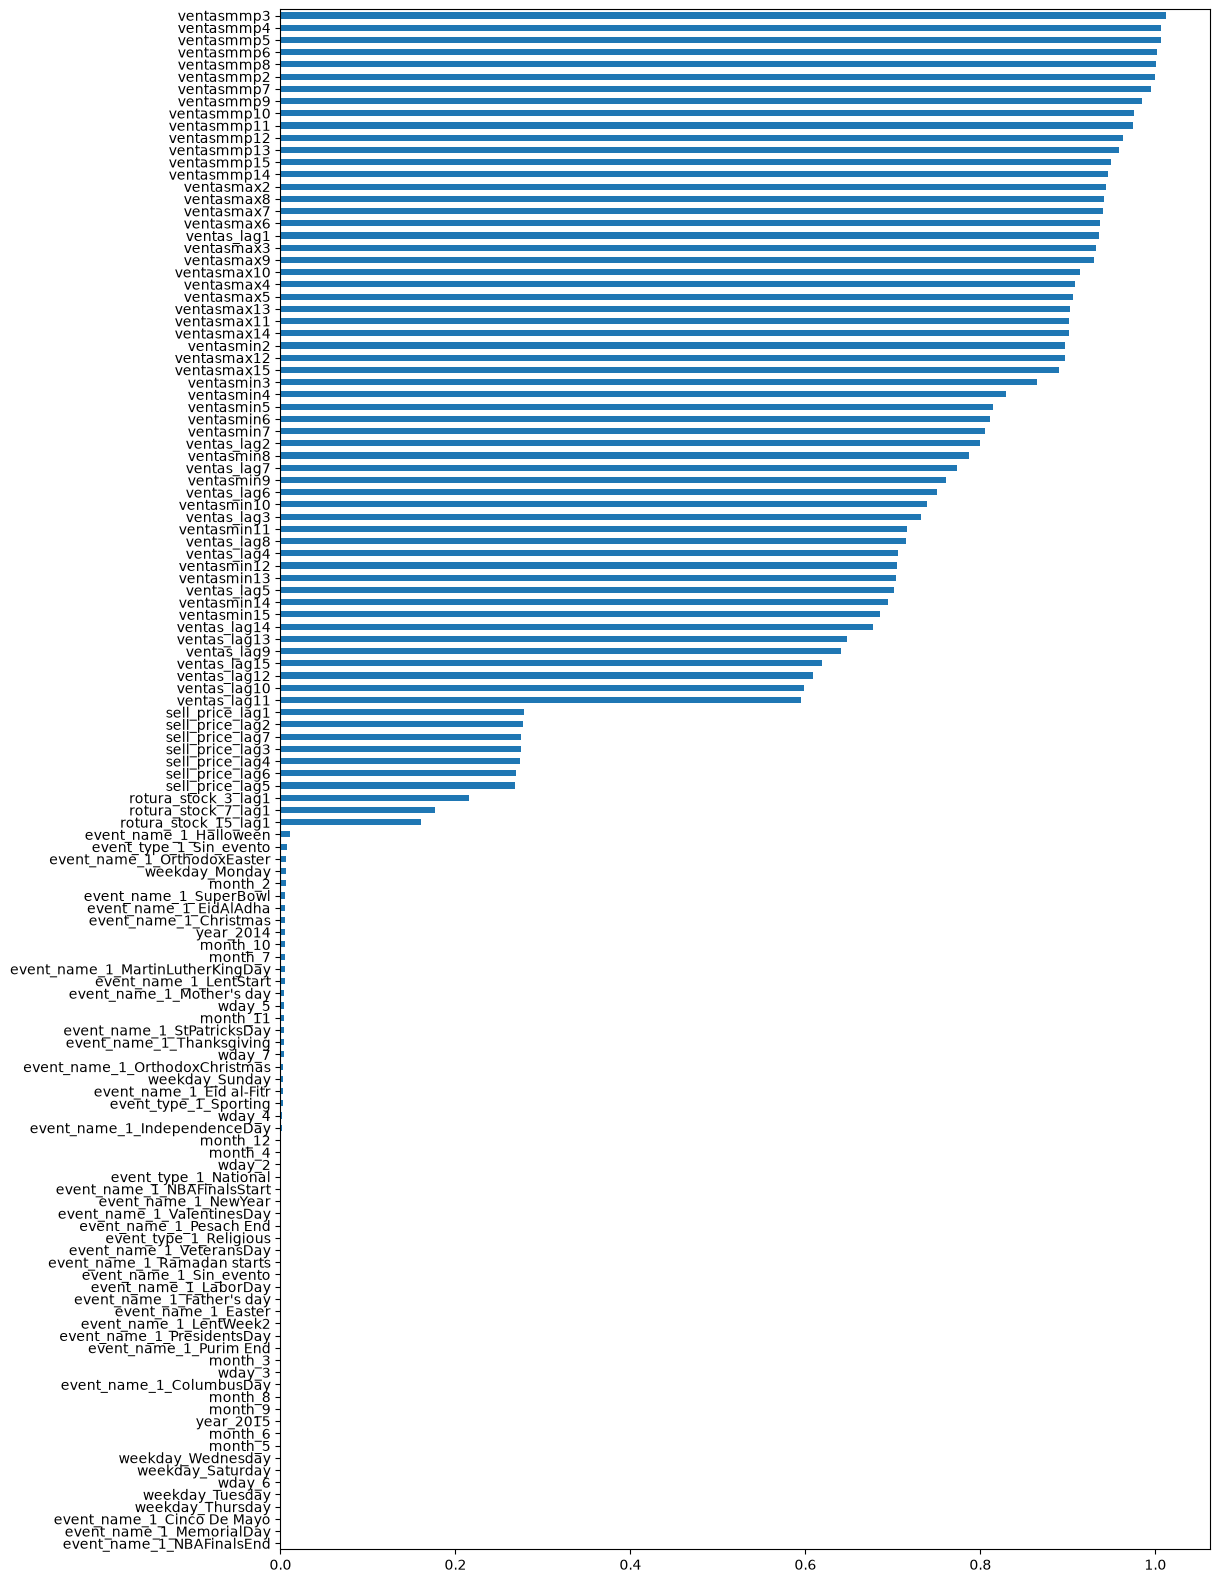

In [34]:
mutual_selector = mutual_info_regression(x,y)

rank_mi = ranking_mi(mutual_selector, modo = 'grafico')

#### Seleccionar las variables que pasan

##### Definir la posición de la última variable que va a entrar

In [35]:
# Vamos a cortar en year_2014 porque segun la grafica parece un corte interesante para borrar pool de variables menos relevantes
ranking_mi(mutual_selector).reset_index().iloc[60:100]

,index,variable,importancia_mi,ranking_mi
60,59,sell_price_lag3,0.27445,60
61,60,sell_price_lag4,0.27417,61
62,62,sell_price_lag6,0.26906,62
63,61,sell_price_lag5,0.26843,63
64,64,rotura_stock_3_lag1,0.21550,64
65,65,rotura_stock_7_lag1,0.17669,65
66,66,rotura_stock_15_lag1,0.16021,66
67,99,event_name_1_Halloween,0.01073,67
68,124,event_type_1_Sin_evento,0.00722,68
69,111,event_name_1_OrthodoxEaster,0.00654,69


##### Extraer los nombres de las que entran

In [36]:
posicion_variable_limite = 75

In [37]:
entran_mi = ranking_mi(mutual_selector).iloc[0:posicion_variable_limite].variable

In [38]:
entran_mi

5                  ventasmmp3
8                  ventasmmp4
11                 ventasmmp5
14                 ventasmmp6
20                 ventasmmp8
                ...          
86             weekday_Monday
72                    month_2
118    event_name_1_SuperBowl
97     event_name_1_EidAlAdha
92     event_name_1_Christmas
Name: variable, Length: 75, dtype: str

##### Crear el dataframe con la selección

In [39]:
x_mi = x[entran_mi].copy()

### Recursive Feature Elimination

#### Salvedad: ¿por qué usamos RFE y no RFECV?

En un primer intento se probó **RFECV** (RFE con validación cruzada) y se descartó por tres motivos:

1. **Es lentísimo.** Con 126 variables y XGBoost, el proceso completo pasa de los 10 minutos (el CV por defecto son 5 folds, así que entrena el modelo muchísimas veces).
2. **La validación cruzada normal no vale en forecasting.** El CV por defecto **mezcla las filas al azar**. Pero aquí las filas están ordenadas en el tiempo y cada producto es una serie. Al mezclar, el modelo "espía" parte del futuro mientras entrena y la nota sale inflada. En series temporales hay que validar **respetando el orden** (entrenar con lo viejo, validar con lo nuevo).
3. **La decisión ya estaba tomada.** Nos quedamos con **RFE** como método general, así que no merece la pena pagar el coste de RFECV para confirmar algo que ya teníamos claro.

**En resumen:** volvemos a **RFE** (que no hace validación cruzada: solo entrena y va quitando la variable menos importante). Como no le decimos cuántas conservar, deja la mitad (63).

**Nota sobre el guardado:** aunque esta selección general no es la definitiva por producto, se guarda igualmente (`x_preseleccionado` + `y_preseleccionado`) porque se va a reutilizar más adelante, junto con la lista de variables identificadoras (`date`, `store_id`, `item_id`) que se reincorporan con `concat`.

#### Instanciar

In [40]:
rfe = RFE(estimator=XGBRegressor(n_jobs=-1,eval_metric='rmse'))

#### Entrenar

In [41]:
rfe.fit(x,y)

,"estimator estimator: ``Estimator`` instanceA supervised learning estimator with a ``fit`` method that providesinformation about feature importance(e.g. `coef_`, `feature_importances_`).","XGBRegressor(...ree=None, ...)"
,"n_features_to_select n_features_to_select: int or float, default=NoneThe number of features to select. If `None`, half of the features areselected. If integer, the parameter is the absolute number of featuresto select. If float between 0 and 1, it is the fraction of features toselect... versionchanged:: 0.24 Added float values for fractions.",None
,"step step: int or float, default=1If greater than or equal to 1, then ``step`` corresponds to the(integer) number of features to remove at each iteration.If within (0.0, 1.0), then ``step`` corresponds to the percentage(rounded down) of features to remove at each iteration.",1
,"verbose verbose: int, default=0Controls verbosity of output.",0
,"importance_getter importance_getter: str or callable, default='auto'If 'auto', uses the feature importance either through a `coef_`or `feature_importances_` attributes of estimator.Also accepts a string that specifies an attribute name/pathfor extracting feature importance (implemented with `attrgetter`).For example, give `regressor_.coef_` in case of:class:`~sklearn.compose.TransformedTargetRegressor` or`named_steps.clf.feature_importances_` in case ofclass:`~sklearn.pipeline.Pipeline` with its last step named `clf`.If `callable`, overrides the default feature importance getter.The callable is passed with the fitted estimator and it shouldreturn importance for each feature... versionadded:: 0.24",'auto'
Name,Type,Value
estimator_ estimator_: ``Estimator`` instanceThe fitted estimator used to select features.,XGBRegressor,"XGBRegressor(...ree=None, ...)"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](126,)","['ventasmin2','ventasmax2','ventasmmp2',...,'event_type_1_Religious', 'event_type_1_Sin_evento','event_type_1_Sporting']"
n_features_ n_features_: intThe number of selected features.,int64,np.int64(63)
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,126
"ranking_ ranking_: ndarray of shape (n_features,)The feature ranking, such that ``ranking_[i]`` corresponds to theranking position of the i-th feature. Selected (i.e., estimatedbest) features are assigned rank 1.","ndarray[int64](126,)","[ 1, 1, 1,...,34,51,32]"


##### Extraer los nombres de las que entran

In [42]:
entran_rfe = x.columns[rfe.support_]


#### Crear el dataframe con la selección

In [43]:
x_rfe = x[entran_rfe].copy()
x_rfe

,ventasmin2,ventasmax2,ventasmmp2,ventasmin3,ventasmax3,ventasmmp3,ventasmin4,ventasmax4,ventasmmp4,ventasmin5,...,month_2,wday_2,wday_3,wday_4,wday_5,wday_7,weekday_Saturday,event_name_1_Christmas,event_name_1_IndependenceDay,event_name_1_Thanksgiving
0,158.00000,206.00000,183.30469,158.00000,281.00000,201.34074,158.00000,351.00000,212.07131,158.00000,...,0.00000,0.00000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000
1,158.00000,191.00000,188.43490,158.00000,206.00000,196.17029,158.00000,281.00000,203.64041,158.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
2,170.00000,191.00000,176.14496,158.00000,191.00000,183.08505,158.00000,206.00000,190.18197,158.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000,0.00000
3,170.00000,224.00000,208.04832,170.00000,224.00000,203.54260,158.00000,224.00000,203.71055,158.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000
4,224.00000,362.00000,310.68277,170.00000,362.00000,282.77145,170.00000,362.00000,267.03019,158.00000,...,0.00000,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20904,6.00000,12.00000,7.41558,3.00000,12.00000,8.06201,3.00000,15.00000,8.51083,3.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000
20905,6.00000,22.00000,17.13853,6.00000,22.00000,15.03101,3.00000,22.00000,13.90650,3.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000,0.00000
20906,10.00000,22.00000,12.37951,6.00000,22.00000,12.51550,6.00000,22.00000,12.34390,3.00000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,1.00000,0.00000,0.00000,0.00000
20907,10.00000,17.00000,15.45984,10.00000,22.00000,14.75775,6.00000,22.00000,14.20634,6.00000,...,0.00000,1.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000


### Por qué entran 63 columnas en RFE

**RFE** significa *Recursive Feature Elimination* (eliminación recursiva de variables). Funciona así:

1. Coge las **126 variables predictoras**.
2. Entrena un modelo (aquí **XGBoost**).
3. Mira cuál es la variable que menos aporta y **la elimina**.
4. Vuelve al paso 2 y repite hasta quedarse con el número de variables que le hayamos pedido.

El problema es que **no le dijimos cuántas quería conservar**. Cuando no se lo indicas, RFE usa su valor por defecto: **la mitad**. Por eso de 126 deja **63** (126 ÷ 2 = 63), que son las que aparecen en `x_rfe`.

**Ojo: esto NO es RFECV.** RFECV probaría varios tamaños con validación cruzada para encontrar el número óptimo de variables. RFE, tal como está usado aquí, simplemente se queda con la mitad que trae por defecto.

**Conclusión:** las 63 variables de RFE son el resultado de **una prueba general**, no la selección definitiva. La selección buena se hará producto a producto (tienda × producto) en la fase de modelización.

### Permutation Importance

#### Crear una función para mostrar el resultado

In [44]:
def ranking_per(predictoras,permutacion):
    ranking_per = pd.DataFrame({'variable': predictoras.columns, 'importancia_per': permutacion.importances_mean}).sort_values(by = 'importancia_per', ascending = False)
    ranking_per['ranking_per'] = np.arange(0,ranking_per.shape[0])
    return(ranking_per)

#### Instanciar y entrenar

In [45]:
xgb = XGBRegressor(njobs=-1, eval_metric='mae')
xgb.fit(x, y)

permutacion = permutation_importance(xgb, x, y, scoring='neg_mean_absolute_percentage_error',
                                     n_repeats=3,n_jobs=-1)

c:\Users\Admin\Desktop\Desktop\CarpetaFisica\Data Detective\Mis Casos(Importante)\PROYECTO 5 - FORECASTING RETAIL\02_FORECASTING\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [21:47:19] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "njobs" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


#### Revisar la salida

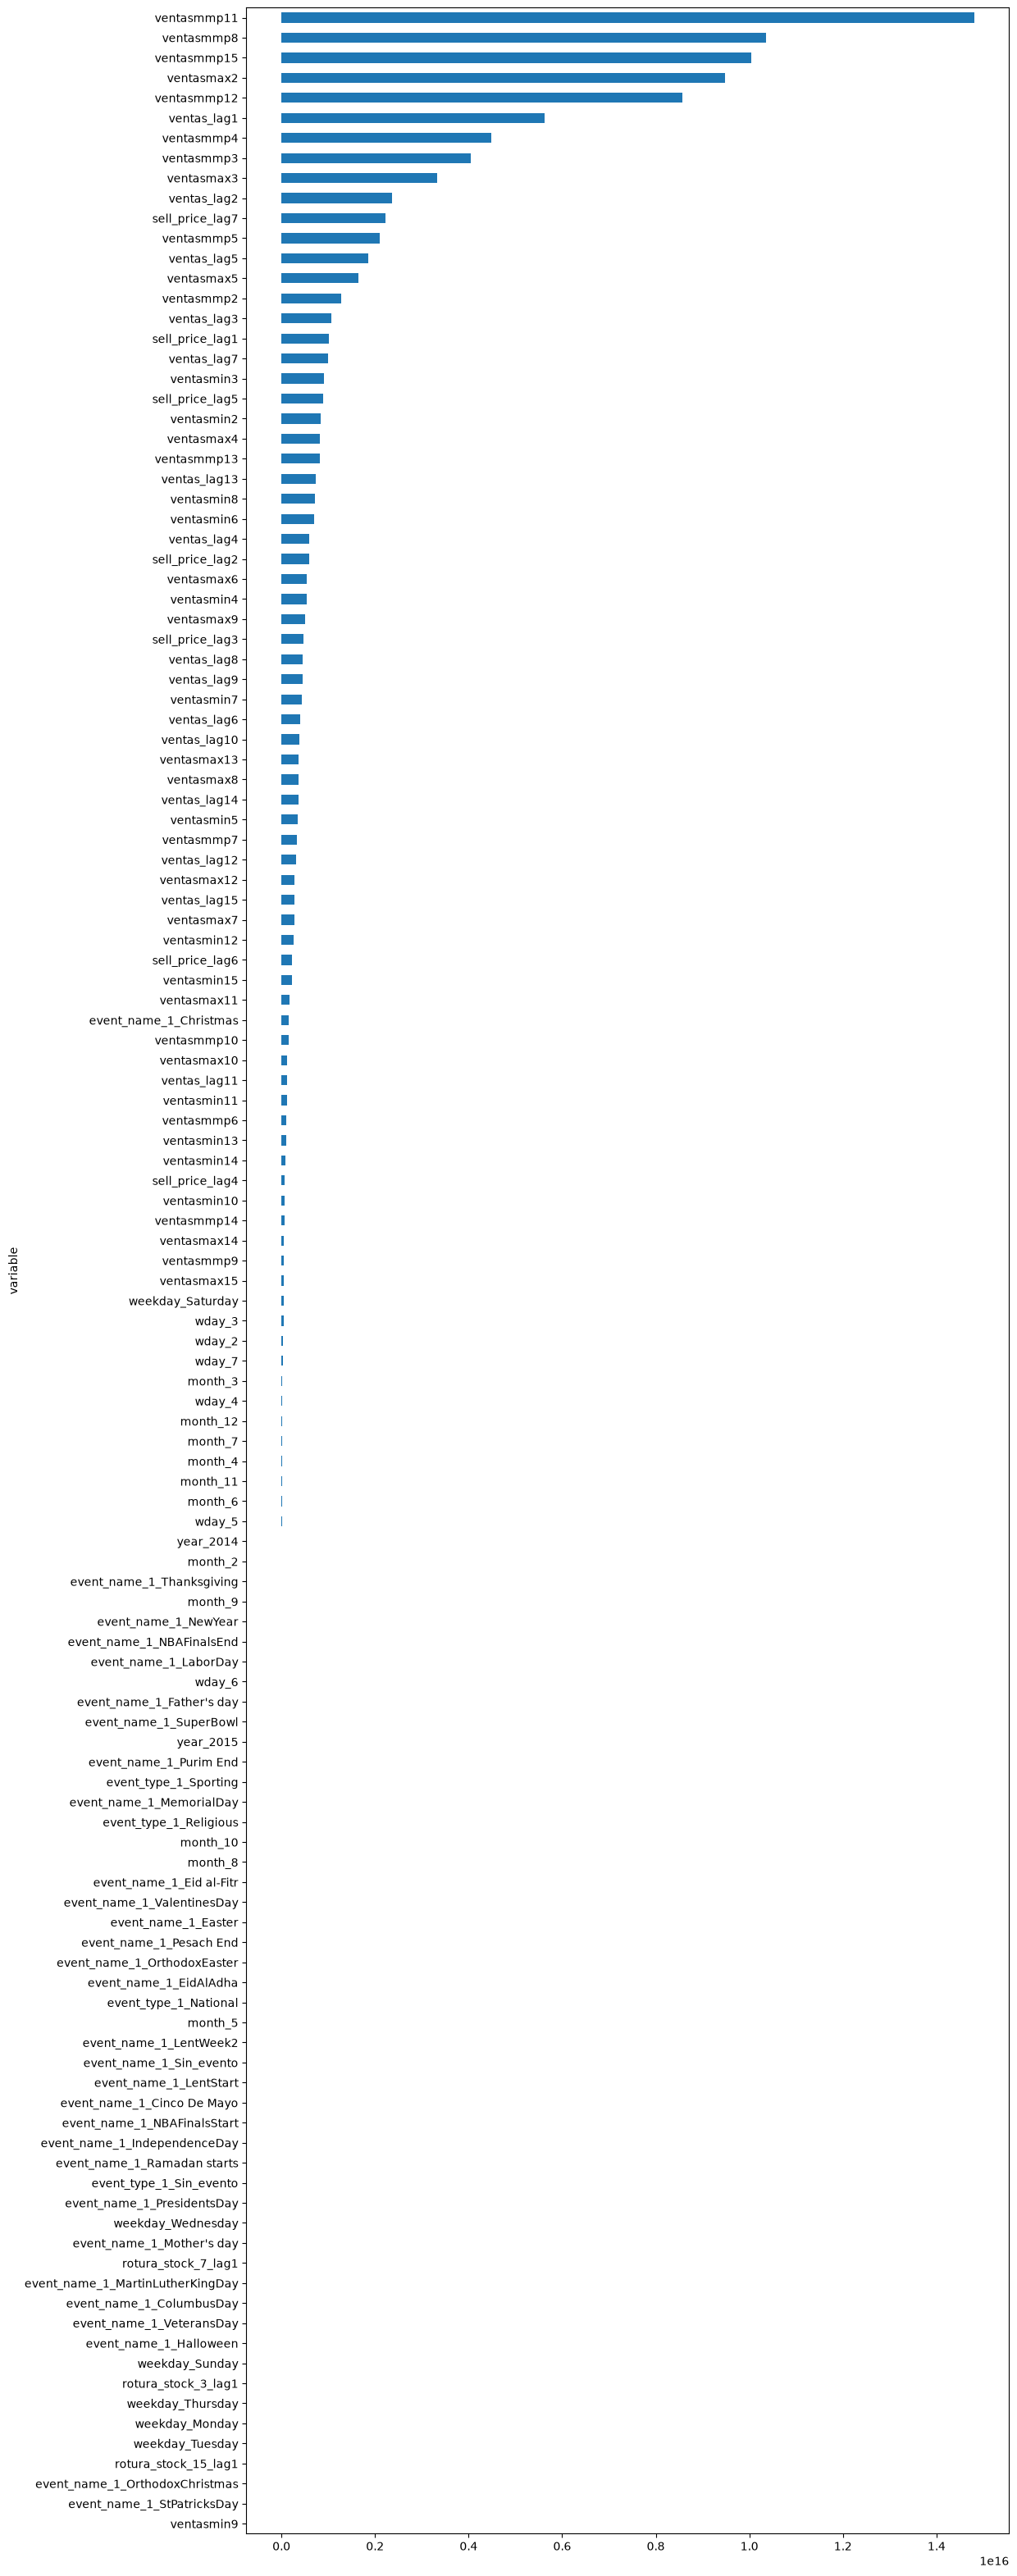

In [46]:
rank_per = ranking_per(x,permutacion)

rank_per.set_index('variable').importancia_per.sort_values().plot.barh(figsize = (12,40));

Con este metodo permutation importance se ve mejor los saltos para cortar mejor, si se tuviera un algoritmo que no selecciona variables como Reg.Logistica, a lo mejor se usaria el Permutation Importance, ya que se ven mejor los saltos

#### Seleccionar las variables que pasan

##### Definir la posición de la última variable que va a entrar

In [47]:
rank_per.reset_index().iloc[50:100]

,index,variable,importancia_per,ranking_per
50,92,event_name_1_Christmas,162300192707925.34375,50
51,26,ventasmmp10,159546537061034.65625,51
52,25,ventasmax10,121898106443093.32812,52
53,52,ventas_lag11,115883228441258.67188,53
54,27,ventasmin11,113412548504234.67188,54
55,14,ventasmmp6,105526720113322.67188,55
56,33,ventasmin13,104388553779882.67188,56
57,36,ventasmin14,81742667623082.67188,57
58,60,sell_price_lag4,70510164923733.32812,58
59,24,ventasmin10,69790086813013.33594,59


##### Extraer los nombres de las que entran

In [48]:
posicion_variable_limite = 74

entran_per = rank_per.iloc[0:posicion_variable_limite].variable

##### Crear el dataframe con la selección

In [49]:
x_per = x[entran_per].copy()

## SELECCIONAR EL MÉTODO FINAL

In [50]:
x_preseleccionado = x_mi
#x_preseleccionado = x_rfe
#x_preseleccionado = x_per

# Como se haran tantos modelos, no se quiere perder mucho el control asi que sera mutual information, ya que si por ejemplo
# en algun producto selecciona poco pool de variables a escoger para lightgbm, se quiere mantener un control consistente.

### Cómo leer la comparación general

Se comparan tres maneras de proponer variables usando el tablón conjunto de entrenamiento:

- **Mutual Information (MI):** mide qué variables parecen aportar información sobre las ventas. Se toman las 75 mejor puntuadas como un recorte práctico, no porque 75 sea un número óptimo demostrado.
- **RFE:** usa la importancia que da XGBoost y conserva 63 variables, la mitad del total, según el valor por defecto explicado arriba.
- **Permutation Importance (PI):** desordena una variable y observa cuánto empeora el error del modelo. Se toman también las 75 primeras del ranking.

Los tamaños no son iguales (75, 63 y 75), por lo que la comparación sirve para revisar coincidencias y diferencias entre listas; no para declarar ganador a un método. Tampoco se están comparando aquí pronósticos finales. La selección definitiva se hará después para cada combinación de tienda y producto.

In [51]:
# ── Reincorporar los identificadores (para reutilizar el dataset) ─────
x_preseleccionado = pd.concat([df[['date','store_id','item_id']], x_preseleccionado], axis=1)

x_preseleccionado.to_pickle("../02_datos/03_Entrenamiento/x_preseleccionado.pkl")
y_preseleccionado = pd.DataFrame({'ventas': y.copy()})
y_preseleccionado.to_pickle("../02_datos/03_Entrenamiento/y_preseleccionado.pkl")

### Salida de esta fase (en cristiano)

**¿Qué hemos hecho aquí?** Comprobar, sobre un tablón general, qué método de selección de variables (MI, RFE y PI) parece más útil. Es un **experimento de prueba**, no un modelo final.

**¿Qué pasa ahora?** Las listas de MI, RFE y PI quedan como referencia para comparar el filtro general. En la fase de **modelización** se recorrerá cada uno de los 20 productos con bucles `for` y, dentro de cada uno, se repetirá este mismo proceso (selección + modelo) con sus propios datos.

**Preparado para el agente de modelización:** el tablón de entrada es `../02_datos/03_Entrenamiento/df_tablon_transformado.pkl`, la variable objetivo es `ventas`, y las columnas a excluir como predictoras son `date`, `store_id` e `item_id`.

### Contexto de esta fase (para que se entienda qué está pasando)

- La preselección de este notebook es una **prueba a nivel general**: se coge el tablón completo (los 20 productos juntos) y se comparan 3 métodos (MI, RFE, PI) para ver cómo se comportan.
- **No es un entregable.** La selección de variables que cuenta se hace **producto a producto**, dentro de los bucles `for` de la modelización; como allí se vuelve a seleccionar, este recorte general es solo una prueba.
- El dataset (`x_preseleccionado.pkl` + `y_preseleccionado.pkl`) se guarda **solo para reutilizarlo en `07_Modelizacion.ipynb`**, donde se repite el mismo trabajo a escala real: recorrer los 20 productos con `for` y, dentro de cada uno, hacer su propia selección (MI) + su modelización con **LightGBM** (parámetros, hiperparámetros, etc.).
- `07_Modelizacion.ipynb` es un notebook de modelización: **tampoco guarda un dataset**.